# Sea-ice climatology: CAMulator vs CESM

Hemispheric **sea-ice area** (10$^6$ km$^2$), as a monthly climatology (Jan to Dec, mean over `YEARS`) and as a full monthly time series.

* **CAMulator**: `aice` (or `IFRAC`) from the per-year cache in `icefrac_cache/<CASE>/`, on native gx1v7, weighted by `TAREA`
* **CESM**: `ICEFRAC` from Will's 6-hourly zarrs, averaged to monthly means and cached once to `icefrac_cache/cesm/`, on native 192x288 lat/lon, weighted by exact cell area

Area = Σ (fraction × cell area). No regridding is needed. CAM `ICEFRAC` is ice / *total* cell area and POP/CICE are ice / *ocean* area, but multiplying by the matching cell area gives true ice area on both sides, so the coastal-dilution trap doesn't apply here.

Everything is in this notebook, with no `ice_ens` imports. Kernel: **npl-2026a**.

In [7]:
import os

import cftime
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

CASE    = "ck70"
YEARS   = (1980, 2014)       # inclusive; CESM zarrs stop at 2014
HEMI    = "north"            # "north" or "south"
CAM_VAR = "aice"             # CAMulator field: "aice" (CICE) or "IFRAC" (POP)

CACHE_ROOT = "/glade/derecho/scratch/tvoeller/honors_thesis/icefrac_cache"
CESM_ROOT  = "/glade/derecho/scratch/wchapman/b_credit_runs"
CESM_ZARR  = "b.e21.CREDIT_climate_branch_1980_{year}_zmdata_ERA5scaled_zmdata_Qtot.zarr"

SAVE    = True
FIG_DIR = f"/glade/work/tvoeller/honors_thesis/code/output/{CASE}/ice_plot/icefrac_climatology"

# Line colours
C_CAM  = "#1f77b4"   # blue
C_CESM = "#ff9f1c"   # orange

years = range(YEARS[0], YEARS[1] + 1)
POLE  = "Arctic" if HEMI == "north" else "Antarctic"

## 1. Build the CESM monthly cache
Run this once. It takes about 4 s per year, and years that are already cached are skipped. Each 6-hourly year is averaged to 12 monthly means (noleap and evenly spaced, so a plain mean is exact).

In [2]:
cesm_dir = os.path.join(CACHE_ROOT, "cesm")
os.makedirs(cesm_dir, exist_ok=True)

for year in years:
    out = os.path.join(cesm_dir, f"icefrac_monthly_{year}.nc")
    if os.path.exists(out):
        continue
    z = xr.open_zarr(os.path.join(CESM_ROOT, CESM_ZARR.format(year=year)))
    monthly = z["ICEFRAC"].groupby("time.month").mean("time").load()
    monthly = monthly.rename(month="time").assign_coords(
        time=[cftime.DatetimeNoLeap(year, m, 15) for m in range(1, 13)],
        year=("time", np.full(12, year, dtype="int32")),
        month=("time", np.arange(1, 13, dtype="int32")))
    monthly.to_dataset(name="ICEFRAC").to_netcdf(out, encoding={"ICEFRAC": {"dtype": "float32"}})
    print("wrote", out)

## 2. Load both sides and compute hemispheric ice area
CAMulator: `TAREA` is in cm$^2$, and land cells (`KMT == 0`) are excluded.
CESM: cell area = R$^2$ · Δλ · (sin φ$_n$ − sin φ$_s$), where the edges are the midpoints between latitude centres, clipped to ±90°.

In [3]:
# ---- CAMulator -------------------------------------------------------------
cam = xr.open_mfdataset([os.path.join(CACHE_ROOT, CASE, f"icefrac_monthly_{y}.nc") for y in years],
                        combine="nested", concat_dim="time", data_vars="minimal",
                        coords="minimal", compat="override")
cam_hemi = (cam["TLAT"] > 0) if HEMI == "north" else (cam["TLAT"] < 0)
cam_w    = cam["TAREA"].where(cam_hemi & (cam["KMT"] > 0), 0) * 1e-10 / 1e6     # cm2 -> 10^6 km2
cam_area = (cam[CAM_VAR].fillna(0) * cam_w).sum(("nlat", "nlon")).load()

# ---- CESM ------------------------------------------------------------------
cesm = xr.open_mfdataset([os.path.join(CACHE_ROOT, "cesm", f"icefrac_monthly_{y}.nc") for y in years],
                         combine="nested", concat_dim="time")
lat  = cesm["latitude"].values
edge = np.clip(np.concatenate([[-90], (lat[:-1] + lat[1:]) / 2, [90]]), -90, 90)
R    = 6371.0                                                    # km
dlon = np.deg2rad(360 / cesm.sizes["longitude"])
row_area = R**2 * dlon * np.diff(np.sin(np.deg2rad(edge))) / 1e6  # 10^6 km2, per cell in each lat row
cesm_w = xr.DataArray(row_area, coords={"latitude": lat}, dims="latitude")
cesm_w = cesm_w.where((cesm["latitude"] > 0) if HEMI == "north" else (cesm["latitude"] < 0), 0)
cesm_area = (cesm["ICEFRAC"].fillna(0) * cesm_w).sum(("latitude", "longitude")).load()

print(f"CESM total sphere area: {row_area.sum() * cesm.sizes['longitude']:.2f} x10^6 km2 (Earth = 510.07)")

CESM total sphere area: 510.06 x10^6 km2 (Earth = 510.07)


## 3. Monthly climatology: line plot
The line is the mean over `YEARS` for each calendar month, and the shading is ±1 standard deviation across years.

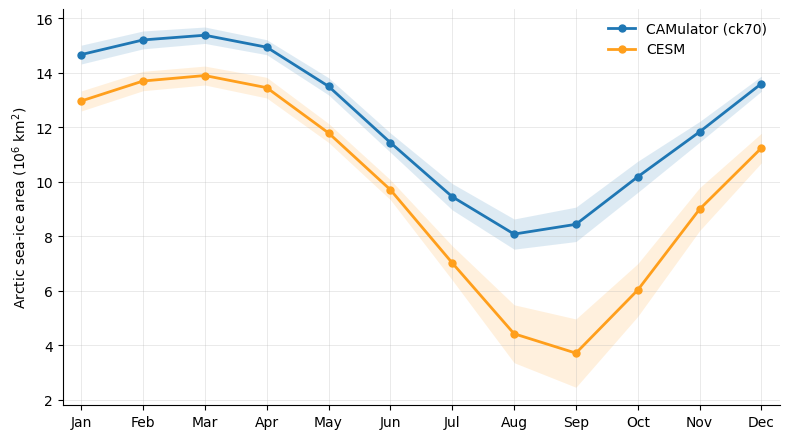

In [12]:
cam_clim  = cam_area.groupby("month")
cesm_clim = cesm_area.groupby("month")
months = np.arange(1, 13)

fig, ax = plt.subplots(figsize=(8, 4.5))
for clim, color, label in [(cam_clim,  C_CAM,  f"CAMulator ({CASE})"),
                           (cesm_clim, C_CESM, "CESM")]:
    mean, std = clim.mean("time"), clim.std("time")
    ax.fill_between(months, mean - std, mean + std, color=color, alpha=0.15, lw=0)
    ax.plot(months, mean, color=color, lw=2, marker="o", ms=5, label=label)

ax.set_xticks(months)
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_xlim(0.7, 12.3)
ax.set_ylabel(f"{POLE} sea-ice area (10$^6$ km$^2$)")
ax.grid(alpha=0.3, lw=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()

if SAVE:
    os.makedirs(FIG_DIR, exist_ok=True)
    fig.savefig(os.path.join(FIG_DIR, f"icefrac_clim_{CASE}_vs_cesm_{POLE.lower()}_{YEARS[0]}-{YEARS[1]}.png"),
                dpi=300, bbox_inches="tight")
plt.show()

## 4. Full monthly time series: line plot

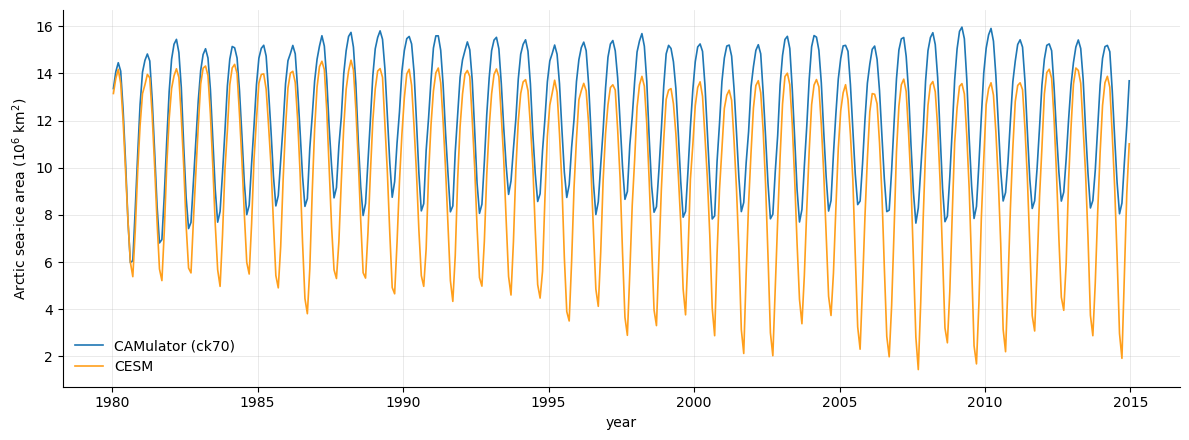

In [10]:
cam_x  = cam_area["year"].values  + (cam_area["month"].values  - 0.5) / 12
cesm_x = cesm_area["year"].values + (cesm_area["month"].values - 0.5) / 12

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(cam_x,  cam_area,  color=C_CAM,  lw=1.2, label=f"CAMulator ({CASE})")
ax.plot(cesm_x, cesm_area, color=C_CESM, lw=1.2, label="CESM")
ax.set_xlabel("year")
ax.set_ylabel(f"{POLE} sea-ice area (10$^6$ km$^2$)")
ax.grid(alpha=0.3, lw=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()

if SAVE:
    fig.savefig(os.path.join(FIG_DIR, f"icefrac_series_{CASE}_vs_cesm_{POLE.lower()}_{YEARS[0]}-{YEARS[1]}.png"),
                dpi=300, bbox_inches="tight")
plt.show()

## 5. Numbers behind the climatology plot

In [6]:
import pandas as pd
pd.DataFrame({"CAMulator": cam_clim.mean("time").values,
              "CESM":      cesm_clim.mean("time").values,
              "CAMulator - CESM": (cam_clim.mean("time") - cesm_clim.mean("time")).values},
             index=["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]).round(2)

,CAMulator,CESM,CAMulator - CESM
Jan,14.66,12.96,1.70
Feb,15.20,13.69,1.51
Mar,15.38,13.90,1.48
Apr,14.94,13.45,1.48
May,13.50,11.79,1.71
Jun,11.43,9.70,1.73
Jul,9.45,7.02,2.43
Aug,8.08,4.42,3.66
Sep,8.44,3.71,4.73
Oct,10.18,6.03,4.15
